# Step 3: the first model, an MLP

An MLP is the same kind of network you build at the end of micrograd: layers of neurons, each one a weighted sum
of its inputs pushed through a squashing function. Here PyTorch does the backprop instead of your `Value` class,
but it's the same idea at a bigger size.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ecg_common as ec

db = ec.load_labels()
X = ec.load_signals(db)
train, val, test = ec.split_masks(db)
keep, y = ec.mi_vs_normal(db)

## Getting the ECGs ready

Two things before the model sees them:

1. **Standardize** each lead using the training ECGs only, so the numbers sit around 0. (Using the test ECGs
   here would leak information about them into training.)
2. **Shrink** each ECG by averaging every 4 time steps: 1,000 steps becomes 250, still 25 per second. An MLP
   takes one flat list of numbers, so each ECG becomes 250 x 12 = 3,000 inputs.

In [2]:
Xs = ec.standardize(X, train)
Xmlp = Xs.reshape(len(Xs), 250, 4, 12).mean(axis=2).reshape(len(Xs), -1)
X_tr, y_tr = Xmlp[train & keep], y[train & keep]
X_va, y_va = Xmlp[val & keep], y[val & keep]
print("training ECGs:", X_tr.shape, "  tuning ECGs:", X_va.shape)

training ECGs: (11622, 3000)   tuning ECGs: (1454, 3000)


## The model

3,000 inputs, a layer of 128 neurons, a layer of 32, and 1 output: the model's "MI score". Dropout switches off a
random 30% of the neurons on each training step, which stops the network from memorizing individual ECGs.

In [3]:
torch.manual_seed(0)
mlp = torch.nn.Sequential(
    torch.nn.Linear(3000, 128), torch.nn.ReLU(), torch.nn.Dropout(0.3),
    torch.nn.Linear(128, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
print(f"{sum(p.numel() for p in mlp.parameters()):,} weights to learn")

388,289 weights to learn


## Training

`ec.train` (in `ecg_common.py`) is the loop from micrograd: run a batch of ECGs through, measure the loss, backprop,
nudge every weight, repeat. One pass through all the training ECGs is an **epoch**. After each epoch it checks
the AUC on the tuning fold and remembers the best version.

In [4]:
history = ec.train(mlp, X_tr, y_tr, X_va, y_va, epochs=25)

epoch  1   training loss 0.645   tuning-fold AUC 0.688


epoch  2   training loss 0.515   tuning-fold AUC 0.761


epoch  3   training loss 0.405   tuning-fold AUC 0.787


epoch  4   training loss 0.326   tuning-fold AUC 0.809


epoch  5   training loss 0.266   tuning-fold AUC 0.798


epoch  6   training loss 0.231   tuning-fold AUC 0.810


... (15 outputs left out)

epoch 22   training loss 0.066   tuning-fold AUC 0.809


epoch 23   training loss 0.067   tuning-fold AUC 0.818


epoch 24   training loss 0.058   tuning-fold AUC 0.822


epoch 25   training loss 0.062   tuning-fold AUC 0.815


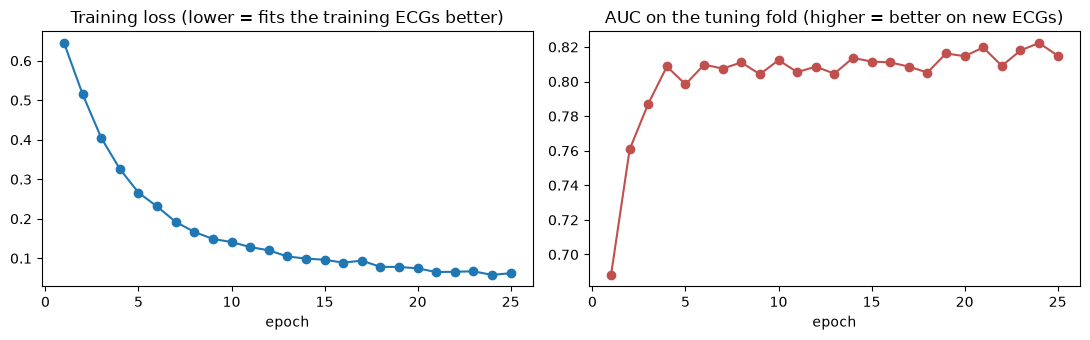

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(history.epoch, history.loss, marker="o")
a.set(title="Training loss (lower = fits the training ECGs better)", xlabel="epoch")
b.plot(history.epoch, history.tuning_auc, marker="o", color="#c0504d")
b.set(title="AUC on the tuning fold (higher = better on new ECGs)", xlabel="epoch")
fig.tight_layout()
fig.savefig("figures/mlp_training.png", dpi=100, bbox_inches="tight")
plt.show()

## How it did

The training loss keeps falling, but the tuning AUC stops improving after a while. That gap is **overfitting**:
the model starts memorizing the training ECGs instead of learning what an MI looks like. That's why `ec.train`
keeps the best version on the tuning fold instead of the last one.

In [6]:
p = ec.predict(mlp, X_va).ravel()
print(f"tuning-fold AUC: {ec.auc(y_va, p):.3f}")
print(f"accuracy at a 50% cut-off: {100 * ((p > 0.5) == y_va).mean():.1f}%")
print(f"MIs caught at a 50% cut-off: {int(((p > 0.5) & (y_va == 1)).sum())} of {int(y_va.sum())}")
torch.save(mlp.state_dict(), "models/mlp_mi.pt")

tuning-fold AUC: 0.822
accuracy at a 50% cut-off: 76.8%
MIs caught at a 50% cut-off: 312 of 540


## What this step showed

- The MLP reaches an AUC of 0.82 on the tuning fold, barely better than ranking by age alone (0.81). At a 50%
  cut-off it catches 312 of 540 MIs (58%).
- It overfits hard: training loss falls from 0.65 to 0.06, so it nearly memorizes the training ECGs, while the
  tuning AUC stalls around 0.81 from epoch 4 on.
- Why: each of its 3,000 inputs is one moment in one lead, and beats land at different times in every strip. The
  MLP has to learn the MI pattern separately for every position, from only 11,622 examples. Step 4 fixes that with
  a network that slides the same detectors along the whole strip.